# 04 · Predicting death: a first machine learning model

**The question:** when a crawler arrives on a floor, can we predict whether they'll die there?

This is **binary classification**: each example (a floor visit) has a label, `died_here` (1 or 0), and we learn to predict it from **features** describing the situation. A good model outputs a *probability* of dying, not just yes or no.

We build up in steps:

1. Frame the data: one row per floor visit, using only what's known **on arrival**.
2. Split into training and test sets the right way (by run, not by row).
3. Fit a simple model (logistic regression), then a more flexible one (gradient boosting).
4. Measure them properly when the event is rare.
5. See how **leakage** can make a useless model look brilliant.
6. Ask which features matter.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score, roc_curve
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from common import MUTED, SEQUENTIAL, SERIES, TEXT_2, load, pct_axis, style, value_grid

style()
floors = load("floors")
print(f"{len(floors):,} floor visits from {floors['run_id'].nunique():,} runs; "
      f"{floors['died_here'].mean():.1%} ended in death")

10,604 floor visits from 2,000 runs; 8.9% ended in death


## 1. Features known on arrival

The rule for a fair prediction: **only use information available at the moment you predict.** On arriving at a floor we know the player's health, level, stats, consumables, gold, class, companion and the floor number. We also know whether they've signed a sponsor contract, since that's decided as the floor starts.

We **must not** use anything that happens *on* the floor, such as damage taken or kills made. Those are consequences of the outcome, not causes we could know in advance.

We also leave out the floor's timer length. On arrival it's exactly $720 + 60 	imes (	ext{depth} - 1)$ minutes, so it carries no information that depth doesn't already. Two **perfectly collinear** features let a linear model split the weight between them arbitrarily, and they make importance measures misleading: shuffling either one breaks the model, so both look vital.

In [2]:
NUMERIC = ["depth", "hp_frac", "max_hp", "level", "power", "defence", "accuracy", "evasion",
           "potions", "bombs", "gold", "boxes", "pet_level"]
assert (floors["timer_max"] == 720 + 60 * (floors["depth"] - 1)).all()    # redundant with depth
CATEGORICAL = ["cls", "pet", "contract", "pet_down"]
LEAKY = ["damage_taken", "kills_here", "gold_earned", "viewers_gained"]      # known only afterwards

floors["pet_down"] = floors["pet_down"].astype(str)
X = floors[NUMERIC + CATEGORICAL]
y = floors["died_here"]
groups = floors["run_id"]
X.describe().T[["mean", "min", "max"]].round(2)

,mean,min,max
depth,3.32,1.0,6.0
hp_frac,0.83,0.3,1.0
max_hp,61.29,36.0,116.0
level,4.91,1.0,14.0
power,10.92,5.0,23.0
defence,4.55,1.0,12.0
accuracy,2.12,0.0,7.0
evasion,0.58,-1.0,3.0
potions,3.10,0.0,14.0
bombs,0.47,0.0,8.0


## 2. Splitting by run, not by row

We train on some data and test on data the model has never seen, to estimate how it will do on *new* runs.

Floor visits from the same run are related: the same companion, class and history. A random row split would put floor 3 of a run in training and floor 4 of that same run in testing, so the model gets a peek at the answer. Splitting by **run** keeps every floor of a run on the same side. This is a `GroupShuffleSplit`.

In [3]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=0)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test, y_train, y_test = X.iloc[train_idx], X.iloc[test_idx], y.iloc[train_idx], y.iloc[test_idx]
assert not set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])     # no run on both sides
print(f"train: {len(X_train):,} rows from {groups.iloc[train_idx].nunique()} runs; "
      f"test: {len(X_test):,} rows from {groups.iloc[test_idx].nunique()} runs")

train: 7,943 rows from 1500 runs; test: 2,661 rows from 500 runs


## 3. Two models

**Logistic regression** fits a weighted sum of the features and squashes it into a probability between 0 and 1. It's simple, fast and easy to read: each weight says which way a feature pushes the risk. Numeric features are standardised and categories are one-hot encoded (one 0/1 column per category).

**Gradient boosting** builds hundreds of small decision trees, each correcting the last one's mistakes. It can capture interactions that a weighted sum can't, such as "low health only matters on floor 6".

In [4]:
prep = ColumnTransformer([("num", StandardScaler(), NUMERIC),
                          ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL)])
logit = make_pipeline(prep, LogisticRegression(max_iter=2000))
gbm = make_pipeline(ColumnTransformer([("num", "passthrough", NUMERIC),
                                       ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                                        CATEGORICAL)]),
                    HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                                   random_state=0))
models = {"logistic regression": logit, "gradient boosting": gbm}
probs = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    probs[name] = model.predict_proba(X_test)[:, 1]
print("fitted")

fitted


## 4. Measuring a rare event

Only about 1 floor in 10 ends in death. A model that always says "you'll live" is right about 90% of the time and completely useless, so **accuracy** is the wrong measure. Instead:

| Metric | What it measures | Useless model scores |
|---|---|---|
| **ROC AUC** | If you pick one death and one survival at random, how often does the model rank the death as riskier? | 0.5 |
| **Average precision** | How well the top-ranked risks are actually deaths (area under the precision-recall curve) | the base rate (~0.1) |
| **Brier score** | Mean squared error of the probabilities; lower is better | about 0.09 for "always the base rate" |

In [5]:
base = y_train.mean()
rows = [dict(model="always predict the base rate", roc_auc=0.5,
             avg_precision=average_precision_score(y_test, np.full(len(y_test), base)),
             brier=brier_score_loss(y_test, np.full(len(y_test), base)))]
for name, p in probs.items():
    rows.append(dict(model=name, roc_auc=roc_auc_score(y_test, p),
                     avg_precision=average_precision_score(y_test, p), brier=brier_score_loss(y_test, p)))
scores = pd.DataFrame(rows).set_index("model")
best_name = scores.drop(index="always predict the base rate")["roc_auc"].idxmax()
best = models[best_name]
print(f"Best on the test set: {best_name}")
scores.style.format("{:.3f}")

Best on the test set: logistic regression


,roc_auc,avg_precision,brier
model,,,
always predict the base rate,0.500,0.091,0.083
logistic regression,0.838,0.422,0.066
gradient boosting,0.820,0.409,0.066


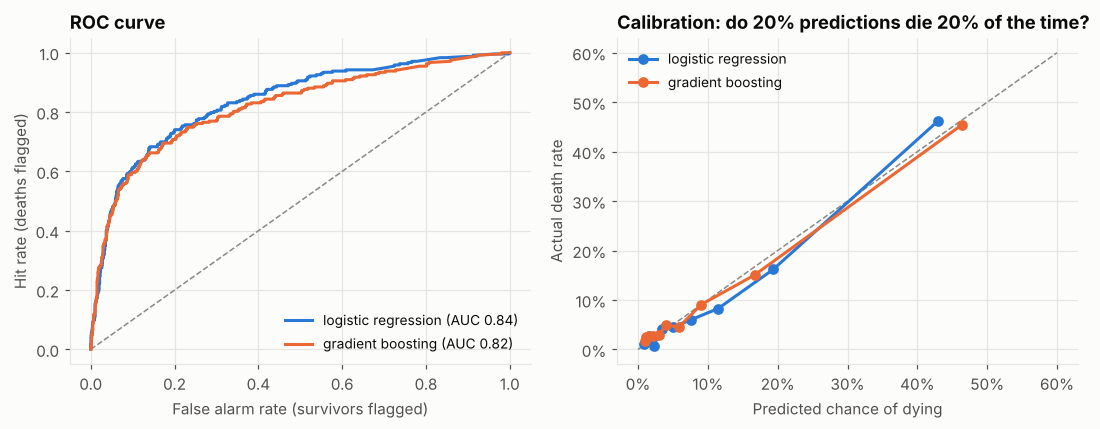

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
ax.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1)
for (name, p), colour in zip(probs.items(), SERIES):
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, color=colour, label=f"{name} (AUC {roc_auc_score(y_test, p):.2f})")
ax.set_xlabel("False alarm rate (survivors flagged)")
ax.set_ylabel("Hit rate (deaths flagged)")
ax.legend(loc="lower right", fontsize=9)
ax.set_title("ROC curve")
ax.grid(axis="x", visible=True)

ax = axes[1]
ax.plot([0, 0.6], [0, 0.6], color=MUTED, linestyle="--", linewidth=1)
for (name, p), colour in zip(probs.items(), SERIES):
    bins = pd.qcut(p, 10, duplicates="drop")
    cal = pd.DataFrame({"p": p, "y": y_test.values}).groupby(bins, observed=True).mean()
    ax.plot(cal["p"], cal["y"], marker="o", color=colour, label=name)
ax.set_xlabel("Predicted chance of dying")
ax.set_ylabel("Actual death rate")
pct_axis(ax)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.legend(loc="upper left", fontsize=9)
ax.set_title("Calibration: do 20% predictions die 20% of the time?")
ax.grid(axis="x", visible=True)
plt.tight_layout()
plt.show()

**The simple model holds its own.** Logistic regression matches or beats gradient boosting here. The risk is mostly a sum of separate effects (deeper floor, riskier deal, weaker character), which is exactly what a weighted sum captures, so the trees' extra flexibility mostly fits noise. Always try the simple model first: it's a benchmark, and sometimes it's the answer. The sections below use whichever model scored best.

The ROC curve shows the trade-off between catching deaths and raising false alarms. The calibration chart checks the probabilities are honest: points on the diagonal mean "a 30% prediction really does die about 30% of the time", which is what you want if you're going to act on the number.

## 5. Two ways to fool yourself

**Leakage.** Add the floor's outcomes (damage taken, kills, gold earned) as if they were known on arrival, and watch the score jump. The model isn't predicting any more; it's reading the answer. Leakage is one of the most common mistakes in real projects, and it usually sneaks in through a column that *looks* innocent.

**The wrong split.** Train and test on a random split of *rows* instead of runs.

In [7]:
def fit_score(Xtr, Xte, ytr, yte, numeric):
    model = make_pipeline(ColumnTransformer([("num", "passthrough", numeric),
                                             ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                                              CATEGORICAL)]),
                          HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05,
                                                         max_leaf_nodes=15, random_state=0))
    model.fit(Xtr, ytr)
    return roc_auc_score(yte, model.predict_proba(Xte)[:, 1])

XL = floors[NUMERIC + LEAKY + CATEGORICAL]
leaky_auc = fit_score(XL.iloc[train_idx], XL.iloc[test_idx], y_train, y_test, NUMERIC + LEAKY)

Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
row_split_auc = fit_score(Xr_tr, Xr_te, yr_tr, yr_te, NUMERIC)

pd.DataFrame({"ROC AUC": {
    "honest: arrival features, split by run": roc_auc_score(y_test, probs["gradient boosting"]),
    "leaky: adds what happened on the floor": leaky_auc,
    "split by row instead of by run": row_split_auc,
}}).style.format("{:.3f}")

,ROC AUC
"honest: arrival features, split by run",0.820
leaky: adds what happened on the floor,0.991
split by row instead of by run,0.823


The leaky model looks far better, and it's useless: you can't know the damage you'll take on a floor before you play it. If a model ever looks too good to be true, check for leakage first.

The row-split score is close to the honest one here, because the bot's runs are fairly independent of each other. With real players, where one person plays many runs in a similar style, splitting by player matters far more.

## 6. What drives the risk?

**Permutation importance** shuffles one feature at a time in the test set and measures how much the model's AUC drops. A big drop means the model relies on that feature. It works for any model and is measured on unseen data.

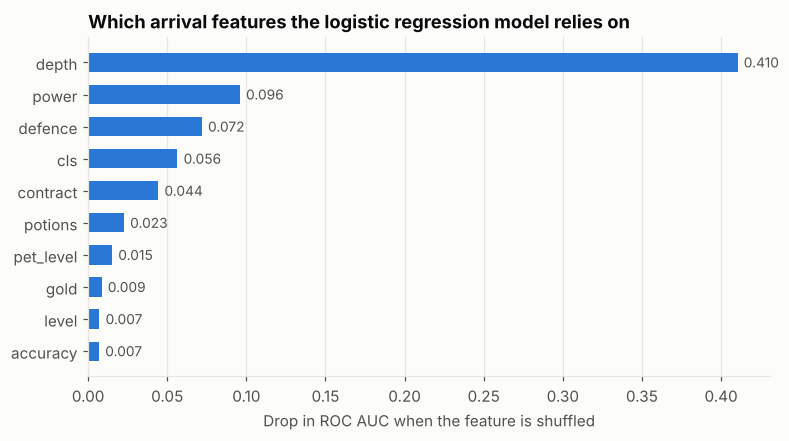

In [8]:
imp = permutation_importance(best, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=0)
importance = (pd.Series(imp.importances_mean, index=X_test.columns).sort_values()
              .rename("AUC lost when shuffled"))
top = importance.tail(10)

fig, ax = plt.subplots(figsize=(8, 4))
y_pos = np.arange(len(top))
ax.barh(y_pos, top.values, color=SEQUENTIAL, height=0.6)
ax.set_yticks(y_pos, top.index)
for yy, v in zip(y_pos, top.values):
    ax.annotate(f"{v:.3f}", (v, yy), xytext=(4, 0), textcoords="offset points", va="center", color=TEXT_2,
                fontsize=9)
value_grid(ax)
ax.set_xlabel("Drop in ROC AUC when the feature is shuffled")
ax.set_title(f"Which arrival features the {best_name} model relies on")
plt.show()

Finally, a **what-if**: take every floor-6 arrival in the test set, set the potions to a fixed number for everyone, and average the predicted risk. This holds everything else equal and asks how much a full pack of potions is worth going into the final boss.

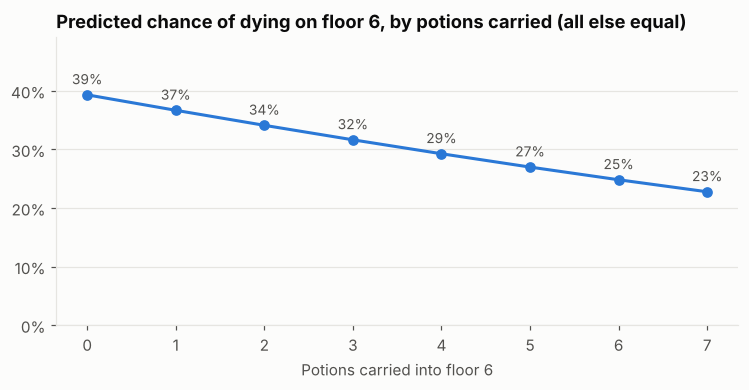

In [9]:
f6 = X_test[X_test["depth"] == 6]
counts = range(0, 8)
risk = []
for n in counts:
    risk.append(best.predict_proba(f6.assign(potions=n))[:, 1].mean())

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(list(counts), risk, marker="o", color=SEQUENTIAL)
for x, r in zip(counts, risk):
    ax.annotate(f"{r:.0%}", (x, r), xytext=(0, 7), textcoords="offset points", ha="center", color=TEXT_2,
                fontsize=9)
ax.set_xlabel("Potions carried into floor 6")
pct_axis(ax)
ax.set_ylim(0, max(risk) * 1.25)
ax.set_title("Predicted chance of dying on floor 6, by potions carried (all else equal)")
plt.show()

**Caution on the what-if.** This is the *model's* view of the bot's behaviour, not a controlled experiment. Players who carry more potions may differ in other ways the features don't capture. For true cause and effect you need randomisation, like the sponsor deals in notebook 01. Treat a model's what-if as a hypothesis to test, not a proof.

**Summary**

- Arrival state predicts floor deaths well (AUC around 0.8), and the probabilities are reasonably calibrated.
- Depth dominates: the final floor is the wall. After that come attack, defence and class, then the sponsor contract (Hazard Pay is the dangerous one, matching notebook 01's experiment) and potions carried.
- Health on arrival barely matters for this bot, because it rests to full before taking the stairs. A feature can be important in general and still be uninformative in a dataset where it hardly varies.
- Leakage can make a model look near-perfect while it predicts nothing.
- Split by the unit that groups your data (runs here, players or stores in real life), or your test score will flatter you.